# Prototype update · missing-data handling

The map now defaults to **available factors**. Dashed segments have only one or two usable factors; popups list exactly what is missing. No observations are replaced with zero.

$$w_e=t_e\left(1+\frac{\sum_{j\in A_e}b_{ej}}{|A_e|}\right)$$

Here `A_e` is the set of known factors for that segment. If none are known, its prototype weight stays unknown.

Use the map selector to compare:
1. **Available factors:** exploratory prototype, default.
2. **Complete data only:** original strict score.
3. **Missing burden = 1:** pessimistic sensitivity assumption.

**Results:** 93,448 / 93,452 edges have a prototype cost; only four have no usable factors. All four candidate origins have routes: 328 / 340 pairs, matching distance-only reachability. Of those routes, 184 change under pessimistic assumptions, so missing-data assumptions materially affect results. These are not validated best or safest routes.

The complete-data equation below remains the special case where all three factors are known. No new data or AI model was trained for this update.


# Full geographic weighted walking graph

This is the full four-ZIP walking network drawn on a map, rather than the schematic activity graph. Junction dots are walking-network nodes, **not houses or residential blocks**. The residential-to-POI graph remains a separate output in Notebook 18.

## Friction equation

$$w_e=\frac{L_e}{v}\left[1+\lambda\left(\alpha(1-C_e)+\beta Q_e+\gamma H_e\right)\right]$$

- **L:** actual segment length in meters.
- **v:** assumed walking speed, 1.2 meters/second.
- **C:** GeoAI-predicted nearby tree fraction, 0–1. More canopy reduces the deficit `1 − C`; this is not measured shade.
- **Q:** normalized traffic burden, 0–1, referenced to Plano.
- **H:** normalized block surface-temperature context, 0–1, referenced to the four-ZIP pilot. This is not segment air temperature.
- **alpha, beta, gamma:** assumed nonnegative factor weights summing to 1; default one-third each.
- **lambda:** assumed penalty strength; default 1.

With these settings, the environmental multiplier ranges from **1× to 2×** ordinary walking time. In complete-data mode, missing required factors produce unknown weights, not zero. The default prototype instead averages available factors and marks partial estimates with dashes.

Example: a two-minute segment with canopy fraction 0.2, traffic 0.7 and heat 0.6 costs `2 × [1 + (0.8 + 0.7 + 0.6)/3] = 3.4 equivalent minutes`. Its actual assumed walking time remains two minutes.

Route cost is the **sum** of these edge weights. Dijkstra chooses the minimum sum for a residential origin and POI. The multiplier is used for map color so long segments are not colored more burdensome solely because of length; clicking shows the actual length-dependent weight.

**Evidence:** the tree layer is a pretrained GeoAI prediction. The factor weights are explicit prototype assumptions, not learned or validated human preferences. Canopy and surface temperature can represent related conditions. Imperviousness and verified crossing difficulty are not included.


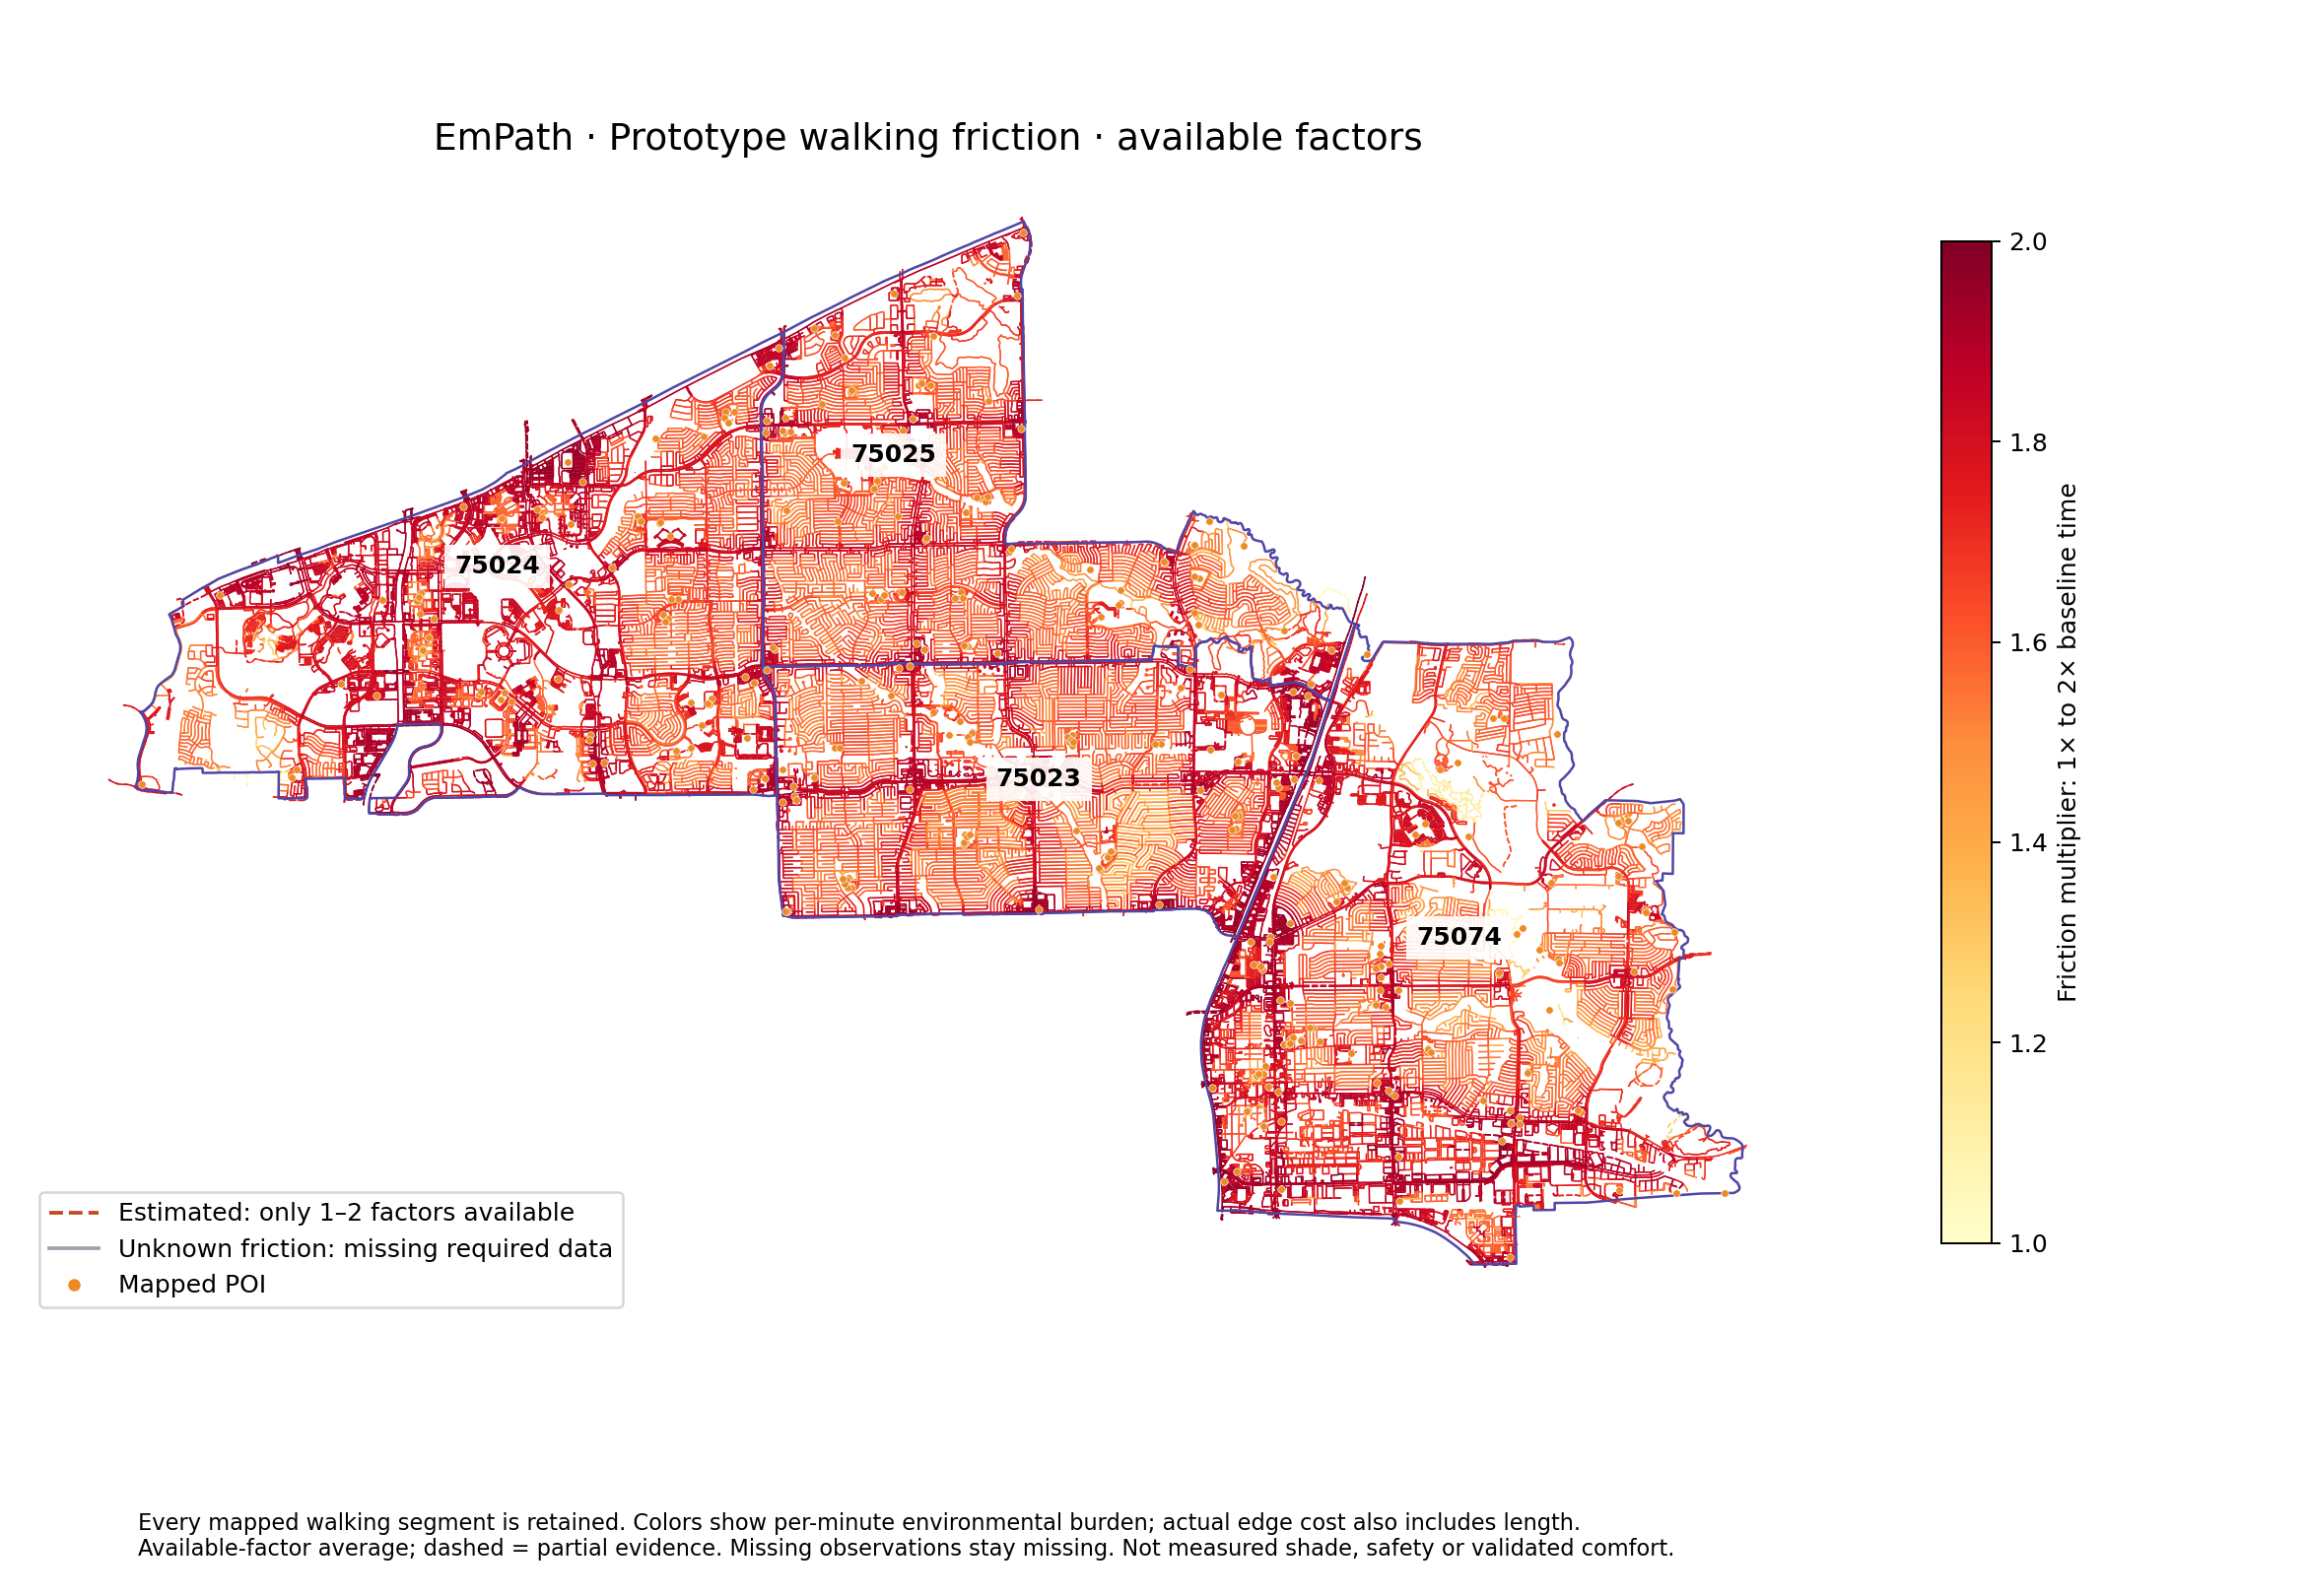

Interactive map: open this file in your browser:
/Users/nalinikantheti/Documents/ChatGPT/EmPath/output/weighted_walking_network/full_weighted_network.html


/Users/nalinikantheti/Documents/ChatGPT/EmPath/output/weighted_walking_network/full_weighted_network.html

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image, FileLink
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'scripts'))
from visualize_weighted_walking_network import run
html_path, png_path = run()
display(Image(filename=str(png_path)))
print('Interactive map: open this file in your browser:')
print(html_path)
display(FileLink(str(html_path)))


## Open the interactive HTML

`output/weighted_walking_network/full_weighted_network.html`

- Pan and zoom across all four ZIP areas.
- Click a walking segment to inspect its exact edge ID, factors, multiplier and weight.
- Toggle graph junction dots, POI categories and ZIP boundaries.
- Toggle the retained residential-to-POI shortest-route segment layer to see only the union of those selected routes.
- In default prototype mode, only segments with no usable factors remain gray. In strict mode, any missing factor appears gray. Use the scoring selector to compare assumptions.

The local map uses the existing private basemap configuration. Do not commit or email authenticated generated HTML. The current site is unchanged by this notebook.

**Files:** interactive HTML, full-network PNG and `weight_equation.json` in the output folder above.
